In [1]:
import os
import torch
from botorch import fit_gpytorch_mll
import botorch_tool
import copy
from botorch.sampling.normal import SobolQMCNormalSampler
from botorch.utils.transforms import unnormalize, normalize, standardize
import numpy as np 
import pandas as pd
import json 
from matplotlib import pyplot as plt 
import pickle
from botorch.utils.transforms import standardize

torch.set_default_dtype(torch.float64)

tkwargs = {"dtype": torch.double,
           "device": torch.device("cuda" if torch.cuda.is_available() else "cpu")}
np.random.seed(42)
torch.manual_seed(42)

In [2]:
with open("./experiment.json", "r") as f:
    exp_data = json.load(f)
exp_data = pd.DataFrame(exp_data)

processed_mass_data = {}
with open("mass_data.pickle", "rb") as f:
    mass_data = pickle.load(f)
with open("current_all.pickle", "rb") as f:
    current_all = pickle.load(f)
for i in mass_data:
    processed_mass_data[list(i.keys())[0]] = list(i.values())[0]
    
error_index = open("异常序号.txt", "r").readlines()[1:]
error_index = [int(i.replace('\n', '')) for i in error_index]

metal_descriptor = pd.read_csv("./metal_descriptor.csv")

In [3]:
failures = []
# read in the data
x = []
y_mean = []
y_var = []
y_current_mean = []
y_current_var = []
for i in range(len(mass_data)):
    if (i not in error_index):
        # get the volume of the first metal 
        var1 = (exp_data.iloc[i]["volume1"]/20 - 0.025)/0.95
        # get the index of the metal 
        metal_index = list(metal_descriptor["metal"]).index(exp_data.iloc[i]["substance1"])
        var2 = metal_descriptor["current"].iloc[metal_index]
        var3 = metal_descriptor["k_HD"].iloc[metal_index]
        x.append([var1, var2, var3])
        # get the mass and current data 
        y_mean.append(processed_mass_data[i].flatten().mean())
        y_var.append(processed_mass_data[i].flatten().var())
        y_current_mean.append(current_all[i].flatten().mean())
        y_current_var.append(current_all[i].flatten().var())
        
x = np.array(x)
y_mean = np.array(y_mean).reshape(-1,1)
y_current_mean = np.array(y_current_mean).reshape(-1,1)
y_var = np.array(y_var).reshape(-1,1)
y_current_var = np.array(y_current_var).reshape(-1,1)
y = np.concatenate([y_mean,y_current_mean],axis = 1)

In [4]:
from sklearn.preprocessing import MinMaxScaler,StandardScaler
scaler_min_max = MinMaxScaler()
scaler_standard = StandardScaler()
x = scaler_min_max.fit_transform(x)
y = scaler_standard.fit_transform(y)

In [5]:
from lazypredict.Supervised import LazyRegressor
from sklearn.model_selection import train_test_split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(x, y[:,0:1],test_size=.2, random_state =123)
reg = LazyRegressor(verbose=0, ignore_warnings=False, custom_metric=None)
models, predictions = reg.fit(X_train, X_test, y_train, y_test)
models
# well, it does not work at all 

 29%|███████████████████████████████████████████████████████████████▏                                                                                                                                                             | 12/42 [00:00<00:01, 25.06it/s]

GammaRegressor model failed to execute
Some value(s) of y are out of the valid range of the loss 'HalfGammaLoss'.


 79%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▋                                               | 33/42 [00:01<00:00, 17.19it/s]

PoissonRegressor model failed to execute
Some value(s) of y are out of the valid range of the loss 'HalfPoissonLoss'.
QuantileRegressor model failed to execute
Solver interior-point is not anymore available in SciPy >= 1.11.0.


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 42/42 [00:02<00:00, 18.10it/s]

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000123 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 139
[LightGBM] [Info] Number of data points in the train set: 333, number of used features: 3
[LightGBM] [Info] Start training from score 0.015381
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, bes

,Adjusted R-Squared,R-Squared,RMSE,Time Taken
Model,,,,
AdaBoostRegressor,0.13,0.16,0.86,0.03
MLPRegressor,0.08,0.11,0.88,0.73
LassoCV,0.04,0.07,0.90,0.09
LassoLarsCV,0.04,0.07,0.90,0.02
LarsCV,0.04,0.07,0.90,0.02
LassoLarsIC,0.04,0.07,0.90,0.01
OrthogonalMatchingPursuit,0.04,0.07,0.90,0.01
OrthogonalMatchingPursuitCV,0.04,0.07,0.90,0.02
ElasticNetCV,0.03,0.07,0.90,0.07


In [7]:
X_train, X_test, y_train, y_test = train_test_split(x, y[:,1:2],test_size=.2, random_state =123)
reg = LazyRegressor(verbose=0, ignore_warnings=False, custom_metric=None)
models, predictions = reg.fit(X_train, X_test, y_train, y_test)
models
# okish, but too weak 

 29%|███████████████████████████████████████████████████████████████▏                                                                                                                                                             | 12/42 [00:00<00:01, 26.47it/s]

GammaRegressor model failed to execute
Some value(s) of y are out of the valid range of the loss 'HalfGammaLoss'.


 79%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▋                                               | 33/42 [00:01<00:00, 18.68it/s]

PoissonRegressor model failed to execute
Some value(s) of y are out of the valid range of the loss 'HalfPoissonLoss'.
QuantileRegressor model failed to execute
Solver interior-point is not anymore available in SciPy >= 1.11.0.


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 42/42 [00:02<00:00, 19.63it/s]

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000088 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 139
[LightGBM] [Info] Number of data points in the train set: 333, number of used features: 3
[LightGBM] [Info] Start training from score 0.013177
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, bes

,Adjusted R-Squared,R-Squared,RMSE,Time Taken
Model,,,,
SVR,0.52,0.54,0.62,0.02
NuSVR,0.52,0.54,0.62,0.03
GradientBoostingRegressor,0.49,0.50,0.64,0.07
HistGradientBoostingRegressor,0.48,0.50,0.64,0.24
LGBMRegressor,0.48,0.50,0.64,0.08
KNeighborsRegressor,0.44,0.46,0.66,0.01
MLPRegressor,0.43,0.45,0.67,0.63
AdaBoostRegressor,0.34,0.37,0.72,0.03
RANSACRegressor,0.27,0.30,0.76,0.09


In [11]:
# initialize the machine learning models for 
train_x = torch.tensor(x)
train_y =torch.tensor(y[:,0:2])
# initialize the model 
mll, model = botorch_tool.tools.initialize_noiseless_model(train_x = train_x,
                                                           train_obj = train_y)
fit_gpytorch_mll(mll)

SumMarginalLogLikelihood(
  (likelihood): LikelihoodList(
    (likelihoods): ModuleList(
      (0-1): 2 x GaussianLikelihood(
        (noise_covar): HomoskedasticNoise(
          (noise_prior): GammaPrior()
          (raw_noise_constraint): GreaterThan(1.000E-04)
        )
      )
    )
  )
  (model): ModelListGP(
    (models): ModuleList(
      (0-1): 2 x SingleTaskGP(
        (likelihood): GaussianLikelihood(
          (noise_covar): HomoskedasticNoise(
            (noise_prior): GammaPrior()
            (raw_noise_constraint): GreaterThan(1.000E-04)
          )
        )
        (mean_module): ConstantMean()
        (covar_module): ScaleKernel(
          (base_kernel): MaternKernel(
            (lengthscale_prior): GammaPrior()
            (raw_lengthscale_constraint): Positive()
          )
          (outputscale_prior): GammaPrior()
          (raw_outputscale_constraint): Positive()
        )
        (outcome_transform): Standardize()
      )
    )
    (likelihood): LikelihoodList

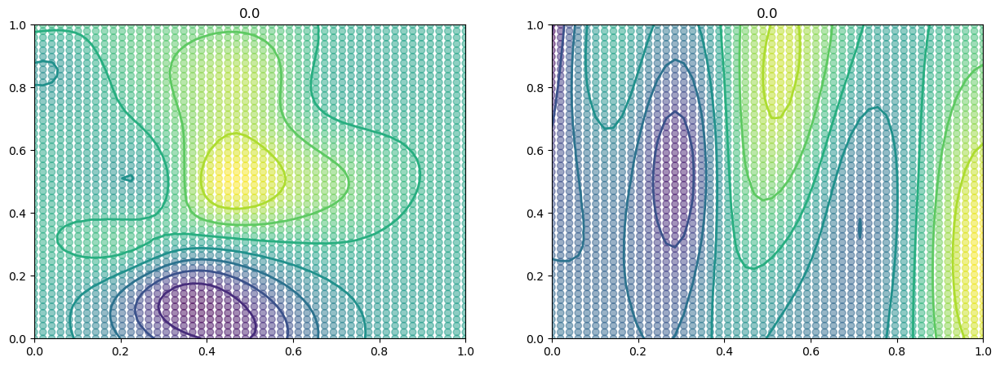

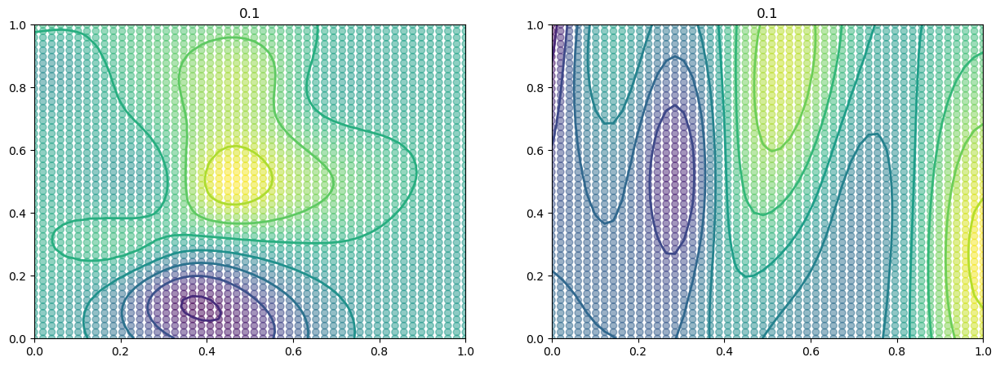

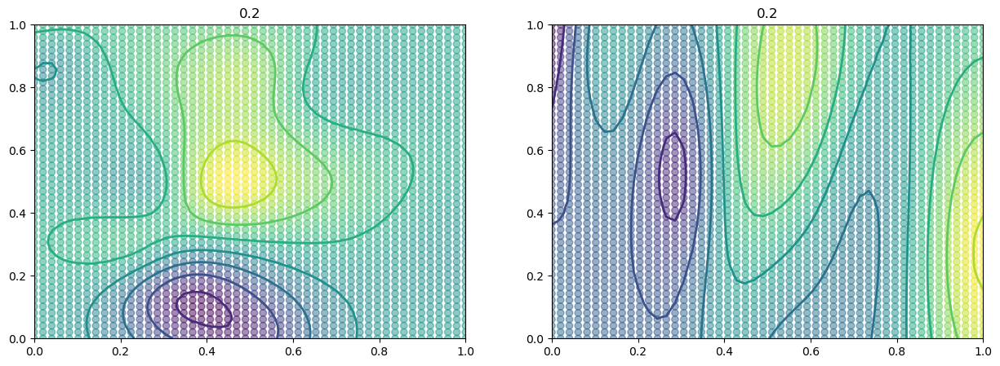

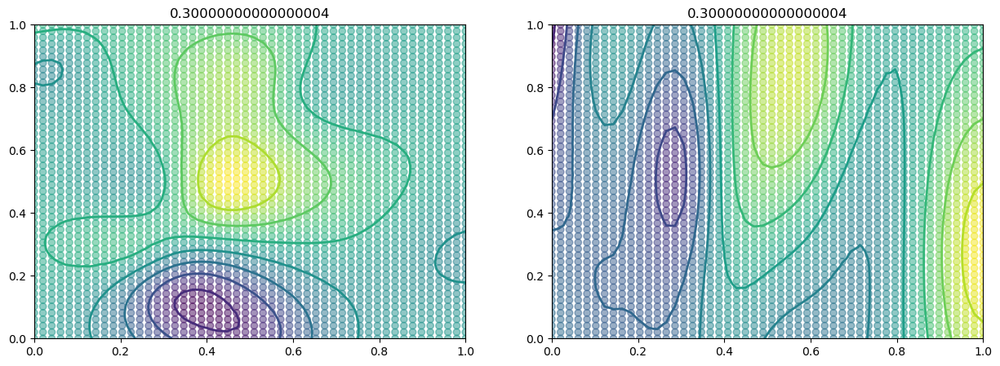

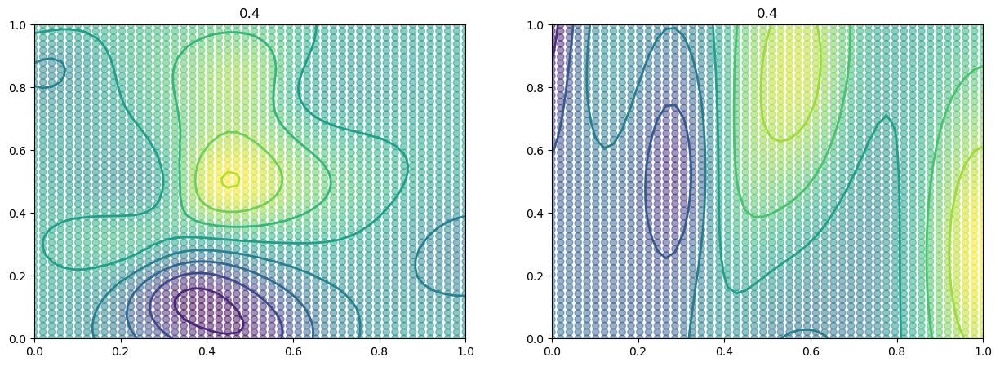

...

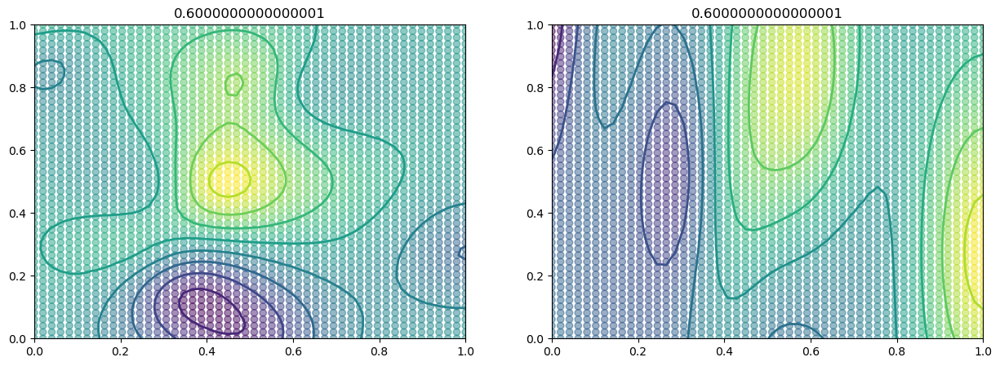

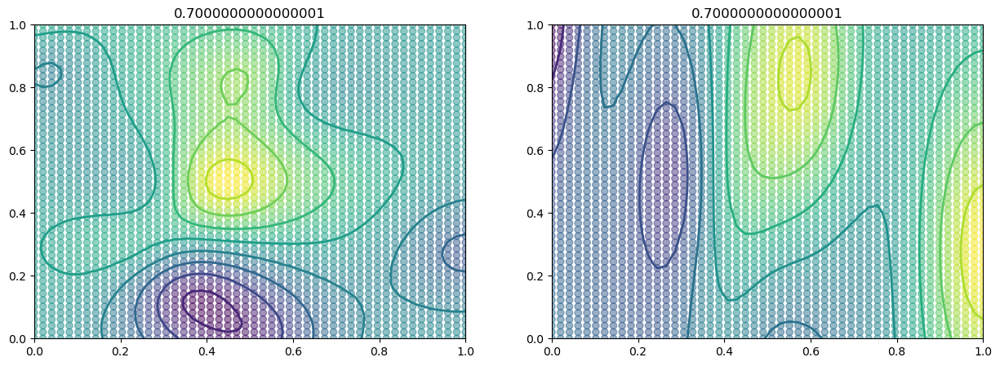

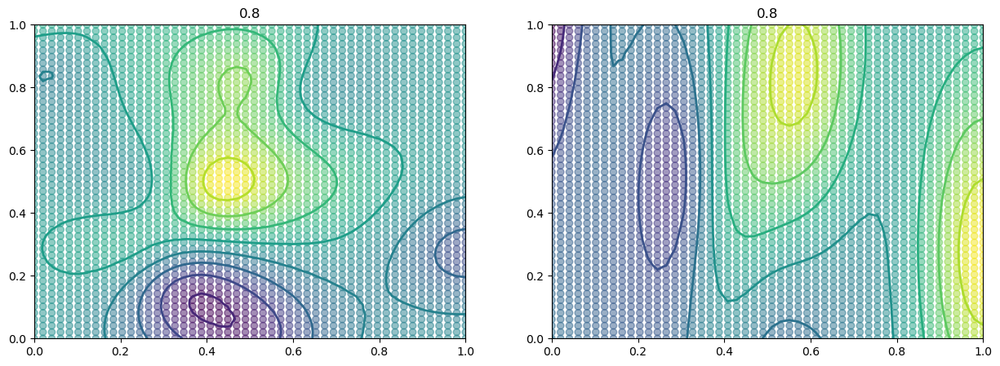

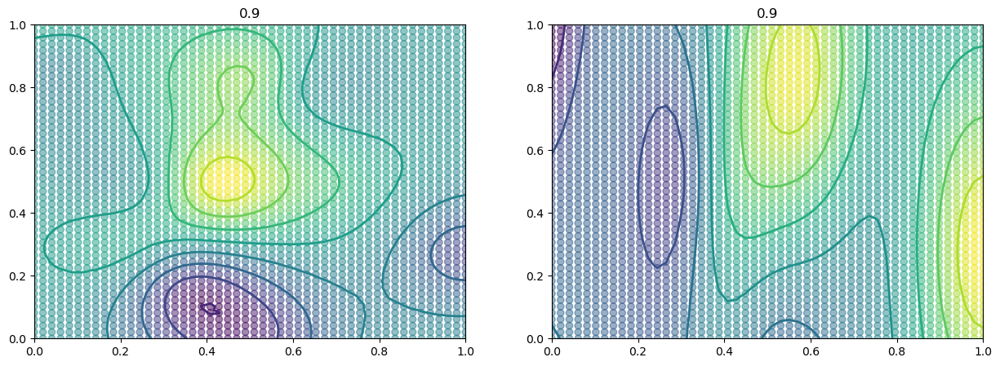

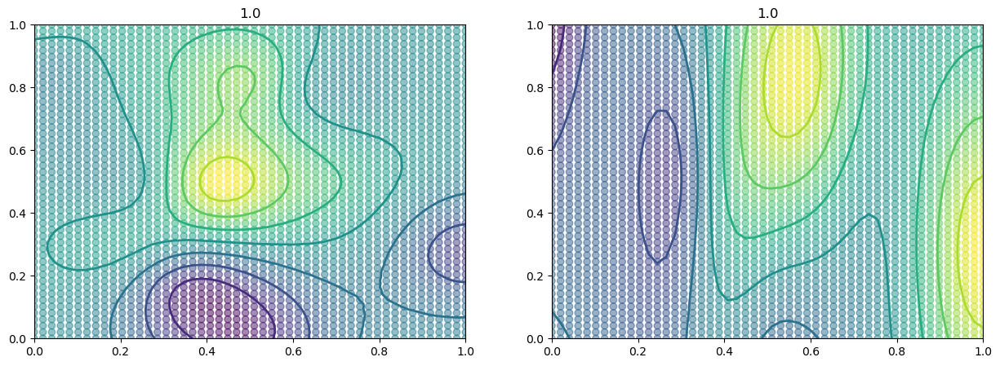

In [66]:
vars = []
for var2 in np.linspace(0,1):
    for var3 in np.linspace(0,1):
        vars.append([0, var2,var3])
vars = np.array(vars)

for conccentration in np.linspace(0,1,11):
    vars[:,0] = conccentration
    results = model.posterior(torch.tensor(vars))
    
    fig, axs = plt.subplots(1, 2, figsize=(15, 5))
    # current
    axs[0].scatter(
        vars[:,1], 
        vars[:,2], 
        c = results.mean.detach().numpy()[:,0], alpha = 0.5)
    axs[0].tricontour(
        vars[:,1], 
        vars[:,2], 
        results.mean.detach().numpy()[:,0], linewidths=2)
    axs[0].set_title(str(conccentration))
    
    # coefficient
    axs[1].scatter(
        vars[:,1], 
        vars[:,2], 
        c = results.mean.detach().numpy()[:,1], alpha = 0.5)
    axs[1].tricontour(
        vars[:,1], 
        vars[:,2], 
        results.mean.detach().numpy()[:,1], linewidths=2)
    axs[1].set_title(str(conccentration))
    plt.show()
    plt.close()